# Initial Test
Here I'm just exploring and testing! I will create a cleaner notebook after I sort things out (model_test.ipynb), and finally I'll create the actual model (predict.py)

In [42]:
# import torch
# from torch.utils.data import dataloader, dataset
import pandas
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.linear_model import Ridge
import numpy as np
import matplotlib.pyplot as plt

In [43]:
csv_raw = pandas.read_csv("../challenge_data/vm_cpu_readings.csv.gz", header=0)

In [44]:
# 1.34M rows, 5 columns
print("Current shape: ", csv_raw.shape)

Current shape:  (1340000, 5)


In [45]:
headers = list(csv_raw.columns[:-1])
y_raw = csv_raw.iloc[:, :].values

print("Headers: \n", headers)

# Every 10k, the timestamp increases by 300.

print("-" * 10)
print("Y - Raw")
print(y_raw[:3], "\n", "-" * 1)
print(y_raw[9999:10002])
print(y_raw[20000:20002])

Headers: 
 ['timestamp', 'vm_id', 'min_cpu', 'max_cpu']
----------
Y - Raw
[[0 'H+FUHUNaeQQvSYHWhak3XW+9PifF0TXQiyYQGEVbDiJoZP8DJEdkl6fl+a5uWHxB'
  1.8121937149020193 14.587021129442396 4.851658938669827]
 [0 'pjJUurJZ7RpWz3MS+oYTDl0CBOeltBhkx7g/e1oB5V6wiWk0Hw8b5VSrGywwP4fY'
  4.126021263986203 5.650850169231353 4.687886046966886]
 [0 'iiljldVGhxG8yYxCrv3jGPpNnvhepXkq21OWoaI9RwsN+QvKWGIHb5Tjrh0ysxXj'
  1.2256690302032818 2.0821111654017854 1.6075881803800098]] 
 -
[[0 '8u6p0Vn0vQ2lss51vL4MKoaron/gZlJQd4x+nWLgK3iUgGR5fJcX9158qk0qFtJe'
  60.111285706114735 73.82219873058204 68.29741608076327]
 [300 '/f+jE9mriEjSsdEzv/qBP0jhMk+EYf9qw928F/sgbwOX2FI27Lff2WvX5m15AN0b'
  1.9745419872976484 2.5625722788988945 2.2577382115887734]
 [300 'axlgaRUC/rriBDz72FFJeXhrXv/Yg30JJpDPZh3VPMRLSD9hatJrCwyJYKYpCAJJ'
  0.3783008174590229 0.938205320538934 0.5574401427148213]]
[[600 'fLgT0pGZYryGeTyfSQtTdcTiDFnNmMk4CLNFaMUWayF6LFb3oKh07sbN85SJj0qB'
  18.870372378757033 55.26709847844988 33.20657339529718]
 [600

In [46]:
# Data validation
# 1. Check for missing data.
missing_cpu = csv_raw["avg_cpu"].isna().sum()
print(f"Missing avg_cpu readings: {missing_cpu}")

# 1.1. Filter unvalid
csv_valid = csv_raw.dropna(subset=["avg_cpu"]).copy()

# 2. Check duplicate VM readings at the same timestamp.
duplicates = csv_raw.duplicated(subset=["timestamp", "vm_id"]).sum()
print(f"Duplicate (timestamp, vm_id) pairs: {duplicates}")

# 2.1. Deduplicate
if duplicates > 0:
    csv_valid = csv_valid.drop_duplicates(subset=["timestamp", "vm_id"])

Missing avg_cpu readings: 0
Duplicate (timestamp, vm_id) pairs: 0


In [47]:
# Once validated, group by timestamps, since we only need to produce forecast for the 'active_vm_count' and 'aggregate_cpu_utilization'.
csv_ts = (
    csv_raw.groupby("timestamp")
    .agg(
        active_vm_count=("vm_id", "nunique"),
        aggregate_cpu_utilization=("avg_cpu", "mean"),
    )
    .reset_index()
    .sort_values("timestamp")
)

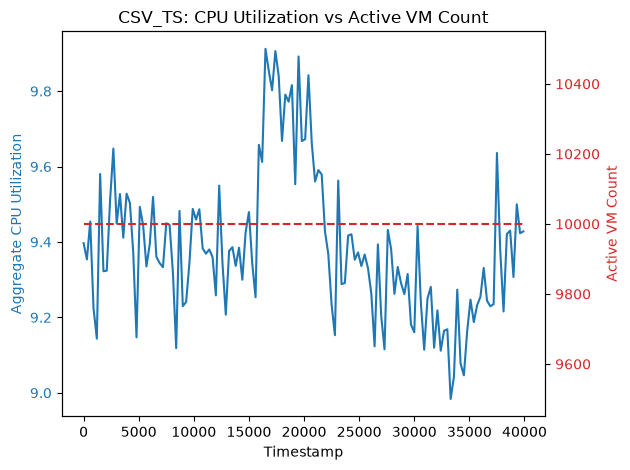

In [48]:
fig, ax1 = plt.subplots()

color1 = 'tab:blue'
ax1.set_ylabel('Aggregate CPU Utilization', color=color1)
ax1.plot(csv_ts.iloc[:, 0], csv_ts.iloc[:, 2], color=color1, label="CPU Util")
ax1.tick_params(axis='y', labelcolor=color1)

ax2 = ax1.twinx() 

color2 = 'tab:red'
ax2.set_ylabel('Active VM Count', color=color2)
ax2.plot(csv_ts.iloc[:, 0], csv_ts.iloc[:, 1], color=color2, linestyle="--", label="VM Count")
ax2.tick_params(axis='y', labelcolor=color2)

ax1.set_xlabel('Timestamp')

plt.title("CSV_TS: CPU Utilization vs Active VM Count")
fig.tight_layout()
plt.show()

In [49]:
# 3. Last check, for any gaps (The readings must be every 5 mins)
# In seconds, 5 minutes = 300 seconds
time_diffs = csv_ts["timestamp"].diff().dropna()
unique_diffs = time_diffs.unique()
print(f"Time differences between consecutive timestamps (seconds): {unique_diffs}")

if len(unique_diffs) == 1 and unique_diffs[0] == 300:
    print(" Grid is continuous (every step is exactly 300s / 5 mins).")
else:
    print(" Warning: Timestamp gaps detected")

print("\nFinal Target Shape:", csv_ts.shape)  # Should be (134, 3)

Time differences between consecutive timestamps (seconds): [300.]
 Grid is continuous (every step is exactly 300s / 5 mins).

Final Target Shape: (134, 3)


In [50]:
print("\nFirst 5 timestamps:")
print(csv_ts.head())
print("-" * 5)
print(csv_ts.tail())


First 5 timestamps:
   timestamp  active_vm_count  aggregate_cpu_utilization
0          0            10000                   9.396898
1        300            10000                   9.353775
2        600            10000                   9.454383
3        900            10000                   9.224419
4       1200            10000                   9.143503
-----
     timestamp  active_vm_count  aggregate_cpu_utilization
129      38700            10000                   9.430236
130      39000            10000                   9.307138
131      39300            10000                   9.499973
132      39600            10000                   9.423042
133      39900            10000                   9.428117


In [51]:
# Data split
train_data = csv_ts[:110]
test_data = csv_ts[110:]

print(train_data.shape) # 110 rows, first 9 hours
print(test_data.shape) # 24 rows, last 2 hours

(110, 3)
(24, 3)


In [52]:
# Baseline prediction
# Grab the very last observation from the training set (row 110)
last_known_row = train_data.iloc[-1]
last_vm_count = last_known_row["active_vm_count"]
last_cpu = last_known_row["aggregate_cpu_utilization"]

print(
    f"Last known point -> Active VMs: {last_vm_count}, CPU: {last_cpu:.2f}%"
)

# Predict that exact value across all 24 holdout timestamps
baseline_preds = pandas.DataFrame(
    {
        "timestamp": test_data["timestamp"].values,
        "active_vm_count": [last_vm_count] * 24,
        "aggregate_cpu_utilization": [last_cpu] * 24,
    }
)

# Check metrics (MAE and RMSE)
for col in ["active_vm_count", "aggregate_cpu_utilization"]:
    actual = test_data[col]
    pred = baseline_preds[col]
    mae = mean_absolute_error(actual, pred)
    rmse = np.sqrt(mean_squared_error(actual, pred))
    print(f"\n[Baseline] {col}:")
    print(f"  MAE:  {mae:.4f}")
    print(f"  RMSE: {rmse:.4f}")

Last known point -> Active VMs: 10000.0, CPU: 9.16%

[Baseline] active_vm_count:
  MAE:  0.0000
  RMSE: 0.0000

[Baseline] aggregate_cpu_utilization:
  MAE:  0.1468
  RMSE: 0.1848


In [53]:
# Save to predictions.csv
baseline_preds.to_csv("test_media/predictions.csv", index=False)

In [54]:

def verification(csv: str):
    sub = pandas.read_csv(csv)
    print("\n--- VERIFICATION ---")
    print("1. Shape is (24, 3)?", sub.shape == (24, 3))
    print(
        "2. Columns correct?",
        list(sub.columns)
        == ["timestamp", "active_vm_count", "aggregate_cpu_utilization"],
    )
    print("3. No NaNs?", sub.isna().sum().sum() == 0)
    print("4. VM count >= 0?", (sub["active_vm_count"] >= 0).all())
    print( "5. CPU in [0, 100]?", ((sub["aggregate_cpu_utilization"] >= 0) & (sub["aggregate_cpu_utilization"] <= 100)).all(),)

verification("test_media/predictions.csv")



--- VERIFICATION ---
1. Shape is (24, 3)? True
2. Columns correct? True
3. No NaNs? True
4. VM count >= 0? True
5. CPU in [0, 100]? True


In [55]:
# We already got a baseline, so now its time to beat MAE: 0.1468 & RMSE: 0.1848
# Since the data is kinda small (110 rows), the simpler the model the better, to prevent overfitting

def create_features(series):
    """Creates lag and rolling features from a univariate CPU series."""
    df_feat = pandas.DataFrame({"cpu": series})

    # Lags (past 5, 10, 15, 30 minutes)
    df_feat["lag_1"] = df_feat["cpu"].shift(1)
    df_feat["lag_2"] = df_feat["cpu"].shift(2)
    df_feat["lag_3"] = df_feat["cpu"].shift(3)
    df_feat["lag_6"] = df_feat["cpu"].shift(6)

    # Rolling statistics over past 30 minutes (6 steps)
    df_feat["rolling_mean_6"] = (
        df_feat["cpu"].shift(1).rolling(window=6).mean()
    )
    df_feat["rolling_std_6"] = df_feat["cpu"].shift(1).rolling(window=6).std()

    # Momentum (change over the last 15 mins)
    df_feat["diff_1"] = df_feat["lag_1"] - df_feat["lag_2"]
    df_feat["diff_3"] = df_feat["lag_1"] - df_feat["lag_3"]

    return df_feat

In [56]:
# Build feature table for the 110 training rows
train_series = train_data["aggregate_cpu_utilization"].copy()
features_df = create_features(train_series)

# Drop initial rows with NaNs caused by lagging
valid_idx = features_df.dropna().index
X_train = features_df.loc[valid_idx].drop(columns=["cpu"])
y_train = features_df.loc[valid_idx, "cpu"]

In [57]:
# We simulate forecasting 24 steps ahead using only the past
print("--- RUNNING TIME-AWARE VALIDATION (Expanding Window) ---")

cv_maes = []
# Test on the last 24 points of the training data (rows 86 to 110)
split_point = 86
X_cv_train, y_cv_train = X_train.loc[: split_point - 1], y_train.loc[
    : split_point - 1
]
X_cv_val, y_cv_val = X_train.loc[split_point:], y_train.loc[split_point:]

cv_model = Ridge(alpha=1.0)
cv_model.fit(X_cv_train, y_cv_train)
cv_preds = cv_model.predict(X_cv_val)

cv_mae = mean_absolute_error(y_cv_val, cv_preds)
print(f"Validation MAE inside training set: {cv_mae:.4f}")

--- RUNNING TIME-AWARE VALIDATION (Expanding Window) ---
Validation MAE inside training set: 0.1038


In [58]:
final_model = Ridge(alpha=1.0)
final_model.fit(X_train, y_train)

# Recursive forecast: predict step 1 -> use it as lag to predict step 2 -> etc.
history = list(train_series.values)
ml_cpu_forecast = []

for step in range(24):
    curr_series = pandas.Series(history)
    curr_feats = create_features(curr_series).iloc[[-1]].drop(columns=["cpu"])

    pred_next = final_model.predict(curr_feats)[0]
    # Bound within [0, 100] as required by contract
    pred_next = float(np.clip(pred_next, 0.0, 100.0))

    ml_cpu_forecast.append(pred_next)
    history.append(pred_next)

print(ml_cpu_forecast)

[9.181416917348098, 9.214106533633874, 9.193645238554243, 9.212224816885637, 9.216626220982366, 9.226585926393945, 9.2245864956766, 9.233872030841813, 9.23622520905091, 9.241888915974867, 9.243470513549779, 9.248554474394531, 9.250783020403064, 9.254526364741434, 9.256571281303152, 9.259764945633709, 9.261771775144515, 9.264352266741081, 9.26618372930308, 9.26837483932674, 9.270042661053152, 9.27188601529873, 9.27337732800462, 9.274954562824364]


In [59]:
actual_test_cpu = test_data["aggregate_cpu_utilization"].values
ml_mae = mean_absolute_error(actual_test_cpu, ml_cpu_forecast)
ml_rmse = np.sqrt(mean_squared_error(actual_test_cpu, ml_cpu_forecast))

print("\n--- FINAL TEST RESULTS ON HOLDOUT ---")
print(f"Baseline MAE: {0.1468:.4f}  |  ML MAE:  {ml_mae:.4f}")
print(f"Baseline RMSE: {0.1848:.4f} |  ML RMSE: {ml_rmse:.4f}")


--- FINAL TEST RESULTS ON HOLDOUT ---
Baseline MAE: 0.1468  |  ML MAE:  0.1032
Baseline RMSE: 0.1848 |  ML RMSE: 0.1373


In [60]:
submission = pandas.DataFrame(
    {
        "timestamp": test_data["timestamp"].values,
        "active_vm_count": [10000.0] * 24,  # Constant from our analysis
        "aggregate_cpu_utilization": ml_cpu_forecast,
    }
)

submission.to_csv("test_media/predictions.csv", index=False)
print("\n 'test_media/predictions.csv' updated successfully!")


 'test_media/predictions.csv' updated successfully!


In [61]:
# Exponential Smoothing
from statsmodels.tsa.api import Holt

# Train data CPU series
train_cpu = train_data["aggregate_cpu_utilization"].values
actual_test_cpu = test_data["aggregate_cpu_utilization"].values

In [62]:

# Fit Holt's Linear Trend with Damping (damped prevents over-projecting trends)
holt_model = Holt(train_cpu, initialization_method="estimated")
# Let it estimate optimal smoothing levels
holt_fit = holt_model.fit(optimized=True)

# Forecast 24 holdout steps
holt_forecast = holt_fit.forecast(24)
holt_forecast = np.clip(holt_forecast, 0.0, 100.0)

# Evaluate Holt
holt_mae = mean_absolute_error(actual_test_cpu, holt_forecast)
holt_rmse = np.sqrt(mean_squared_error(actual_test_cpu, holt_forecast))

print("--- MODEL COMPARISON ---")
print(f"1. Baseline Persistence : MAE = 0.1468 | RMSE = 0.1848")
print(f"2. Recursive Ridge ML    : MAE = 0.1032 | RMSE = 0.1373")
print(f"3. Damped Holt's Smoother: MAE = {holt_mae:.4f} | RMSE = {holt_rmse:.4f}")

# Whichever is best, write it to predictions.csv
best_forecast = (
    holt_forecast
    if holt_mae < 0.1032
    else submission["aggregate_cpu_utilization"]
)
submission["aggregate_cpu_utilization"] = best_forecast
submission.to_csv("test_media/predictions.csv", index=False)

--- MODEL COMPARISON ---
1. Baseline Persistence : MAE = 0.1468 | RMSE = 0.1848
2. Recursive Ridge ML    : MAE = 0.1032 | RMSE = 0.1373
3. Damped Holt's Smoother: MAE = 0.1686 | RMSE = 0.2080
